# Student Social Media Addiction: Dataset Inspection

**Contributor:** Md Sabbir Hossain Tamim

**Objective:** Explore the dataset and check its quality before
preprocessing and model training.

In [3]:
from pathlib import Path
import pandas as pd

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

dataset_path = (
    project_root / "data" / "Students-Social-Media-Addiction-1.csv"
)

df = pd.read_csv(dataset_path)

print("Number of students:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Number of students: 705
Number of columns: 13


,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7


## Dataset Structure and Quality Checks

Inspect column names, data types, missing values, and duplicate records.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 705 entries, 0 to 704
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Student_ID                     705 non-null    int64  
 1    Age                           705 non-null    int64  
 2    Gender                        705 non-null    str    
 3    Academic_Level                705 non-null    str    
 4    Country                       705 non-null    str    
 5    Avg_Daily_Usage_Hours         705 non-null    float64
 6    Most_Used_Platform            705 non-null    str    
 7    Affects_Academic_Performance  705 non-null    str    
 8    Sleep_Hours_Per_Night         705 non-null    float64
 9    Mental_Health_Score           705 non-null    int64  
 10   Relationship_Status           705 non-null    str    
 11   Conflicts_Over_Social_Media   705 non-null    int64  
 12   Addicted_Score                705 non-null    int64  
dtypes

In [6]:
print("Exact duplicate rows:", df.duplicated().sum())

# Check matching records without the unique student identifier.
non_id_columns = [
    column for column in df.columns
    if column.lower() != "student_id"
]

print(
    "Matching rows excluding Student_ID:",
    df.duplicated(subset=non_id_columns).sum()
)

Exact duplicate rows: 0
Matching rows excluding Student_ID: 1


In [7]:
df.describe().round(2)

,Student_ID,Age,Avg_Daily_Usage_Hours,Sleep_Hours_Per_Night,Mental_Health_Score,Conflicts_Over_Social_Media,Addicted_Score
count,705.00,705.00,705.00,705.00,705.00,705.00,705.00
mean,353.00,20.66,4.92,6.87,6.23,2.85,6.44
std,203.66,1.40,1.26,1.13,1.11,0.96,1.59
min,1.00,18.00,1.50,3.80,4.00,0.00,2.00
25%,177.00,19.00,4.10,6.00,5.00,2.00,5.00
50%,353.00,21.00,4.80,6.90,6.00,3.00,7.00
75%,529.00,22.00,5.80,7.70,7.00,4.00,8.00
max,705.00,24.00,8.50,9.60,9.00,5.00,9.00


In [9]:
# Remove spaces from the beginning and end of column names.
df.columns = df.columns.str.strip()

print("Total missing values:", df.isna().sum().sum())
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated student IDs:", df["Student_ID"].duplicated().sum())

Total missing values: 0
Exact duplicate rows: 0
Repeated student IDs: 0


In [10]:
# Display every row involved in a match, ignoring Student_ID.
comparison_columns = df.columns.drop("Student_ID")

matching_rows = df[
    df.duplicated(subset=comparison_columns, keep=False)
]

display(matching_rows)

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
241,242,21,Male,Graduate,Italy,5.4,Instagram,Yes,6.7,5,Single,3,7
273,274,21,Male,Graduate,Italy,5.4,Instagram,Yes,6.7,5,Single,3,7


In [11]:
categorical_columns = df.select_dtypes(
    include=["object", "string"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(df[column].value_counts(dropna=False).to_string())


Gender
Gender
Female    353
Male      352

Academic_Level
Academic_Level
Undergraduate     353
Graduate          325
High School        27

Country
Country
India              53
USA                40
Canada             34
France             27
Spain              27
Mexico             27
Denmark            27
Switzerland        27
Ireland            27
Turkey             27
UK                 22
Japan              21
Italy              21
Russia             21
Bangladesh         20
Pakistan           19
Nepal              19
Sri Lanka          19
Maldives           19
China              16
Poland             16
Australia          14
Germany            14
South Korea        13
Brazil              8
Netherlands         8
New Zealand         8
Singapore           8
Malaysia            8
UAE                 8
Finland             8
Sweden              1
Norway              1
Belgium             1
Austria             1
Portugal            1
Greece              1
Thailand            1
Vietnam

In [12]:
for column in categorical_columns:
    values = df[column].dropna().astype(str)

    print(f"\n{column}")
    print("Unique labels:", sorted(values.unique().tolist()))
    print("Blank entries:", values.str.strip().eq("").sum())
    print(
        "Entries with surrounding spaces:",
        values.ne(values.str.strip()).sum()
    )


Gender
Unique labels: [' Female', ' Male  ']
Blank entries: 0
Entries with surrounding spaces: 705

Academic_Level
Unique labels: [' Graduate      ', ' High School   ', ' Undergraduate ']
Blank entries: 0
Entries with surrounding spaces: 705

Country
Unique labels: [' Afghanistan    ', ' Albania        ', ' Andorra        ', ' Argentina      ', ' Armenia        ', ' Australia      ', ' Austria        ', ' Azerbaijan     ', ' Bahamas        ', ' Bahrain        ', ' Bangladesh     ', ' Belarus        ', ' Belgium        ', ' Bhutan         ', ' Bolivia        ', ' Bosnia         ', ' Brazil         ', ' Bulgaria       ', ' Canada         ', ' Chile          ', ' China          ', ' Colombia       ', ' Costa Rica     ', ' Croatia        ', ' Cyprus         ', ' Czech Republic ', ' Denmark        ', ' Ecuador        ', ' Egypt          ', ' Estonia        ', ' Finland        ', ' France         ', ' Georgia        ', ' Germany        ', ' Ghana          ', ' Greece         ', ' Hong Kong 

### Dataset Quality Findings

- The dataset contains **705 records and 13 columns**.
- There are **7 numerical columns**, including the student identifier, and **6 categorical columns**.
- No missing values or blank categorical entries were detected.
- There are **no exact duplicate rows**.
- Students **242 and 274** have identical values across all columns except `Student_ID`. Both records are retained because matching answers alone do not establish a data error.
- All **705 values in each categorical column** contain leading or trailing whitespace.
- Academic levels are unevenly represented: 353 undergraduates, 325 graduates, and 27 high school students.

**Recommended preprocessing:** Remove leading and trailing whitespace from categorical values while preserving spaces within labels such as “High School” and “In Relationship.”

## Exploratory Data Analysis

Examine the distributions of addiction scores and daily social-media usage.

In [13]:
import matplotlib.pyplot as plt

df_eda = df.copy()
df_eda.columns = df_eda.columns.str.strip()

text_columns = df_eda.select_dtypes(
    include=["object", "string"]
).columns

for column in text_columns:
    df_eda[column] = df_eda[column].str.strip()

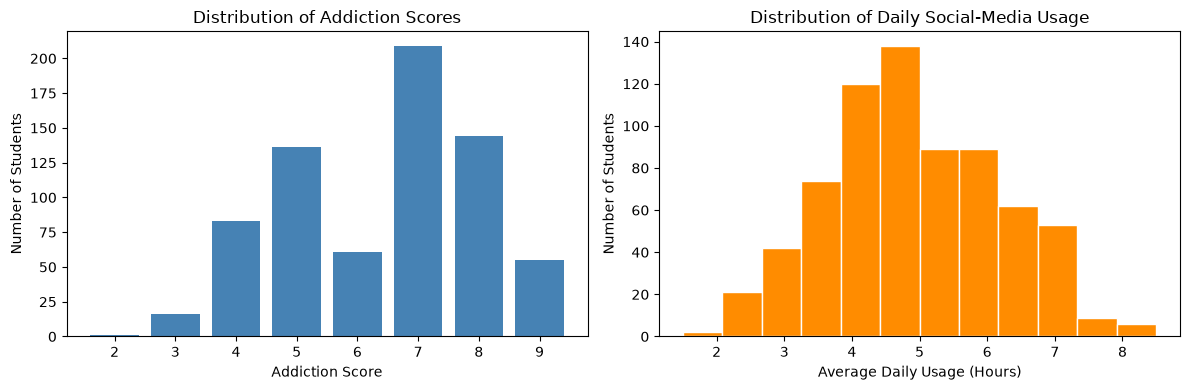

Most common addiction score(s): [7]
Mean daily usage: 4.92 hours
Median daily usage: 4.8 hours


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count students at each observed addiction score.
score_counts = df_eda["Addicted_Score"].value_counts().sort_index()

axes[0].bar(score_counts.index, score_counts.values, color="steelblue")
axes[0].set_title("Distribution of Addiction Scores")
axes[0].set_xlabel("Addiction Score")
axes[0].set_ylabel("Number of Students")
axes[0].set_xticks(score_counts.index)

# Group daily usage into intervals.
axes[1].hist(
    df_eda["Avg_Daily_Usage_Hours"],
    bins=12,
    color="darkorange",
    edgecolor="white"
)
axes[1].set_title("Distribution of Daily Social-Media Usage")
axes[1].set_xlabel("Average Daily Usage (Hours)")
axes[1].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

print("Most common addiction score(s):",
      df_eda["Addicted_Score"].mode().tolist())
print("Mean daily usage:",
      round(df_eda["Avg_Daily_Usage_Hours"].mean(), 2), "hours")
print("Median daily usage:",
      round(df_eda["Avg_Daily_Usage_Hours"].median(), 2), "hours")

### Interpretation

- The addiction-score chart shows how students are distributed across the observed scores.
- Average daily social-media usage is approximately **4.92 hours**, while the median is **4.80 hours**.
- Daily usage ranges from **1.5 to 8.5 hours**.
- These charts describe the sample; they do not establish that social-media usage causes addiction.

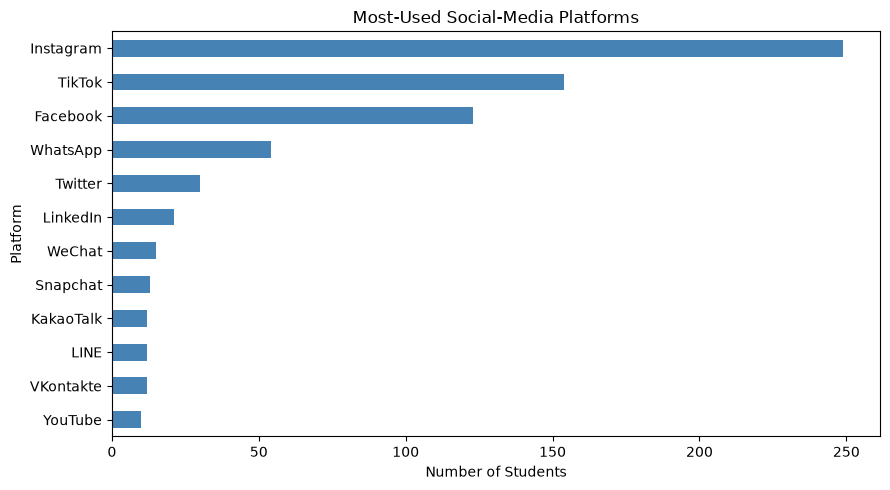

Most_Used_Platform
Instagram    249
TikTok       154
Facebook     123
WhatsApp      54
Twitter       30
LinkedIn      21
WeChat        15
Snapchat      13
LINE          12
KakaoTalk     12
VKontakte     12
YouTube       10


In [15]:
platform_counts = df_eda["Most_Used_Platform"].value_counts()

platform_counts.sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Most-Used Social-Media Platforms")
plt.xlabel("Number of Students")
plt.ylabel("Platform")
plt.tight_layout()
plt.show()

print(platform_counts.to_string())

### Platform Distribution Findings

- Instagram is the most-used platform: **249 students (35.3%)**.
- TikTok follows with **154 students (21.8%)**, then Facebook with **123 (17.4%)**.
- Together, these three platforms account for **74.5%** of the sample.
- Platform groups are uneven in size, so comparisons involving smaller groups should be interpreted cautiously.
- These percentages describe this dataset, not all students.

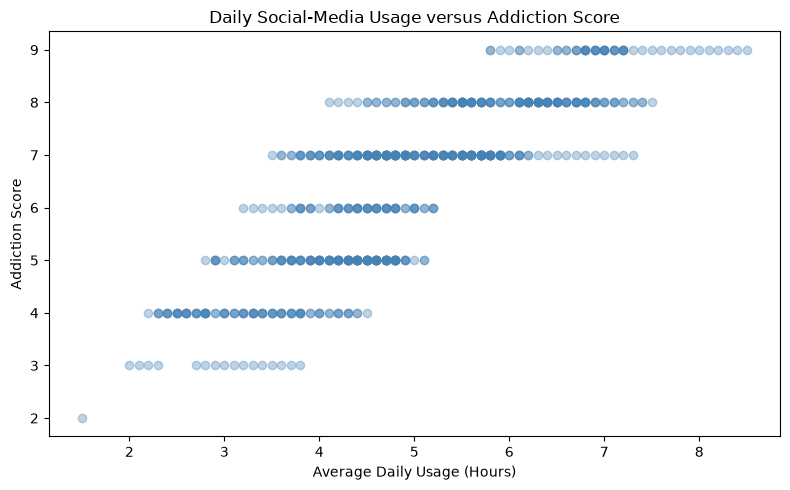

Pearson correlation: 0.832


In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_eda["Avg_Daily_Usage_Hours"],
    df_eda["Addicted_Score"],
    alpha=0.35,
    color="steelblue"
)

plt.title("Daily Social-Media Usage versus Addiction Score")
plt.xlabel("Average Daily Usage (Hours)")
plt.ylabel("Addiction Score")
plt.tight_layout()
plt.show()

correlation = df_eda["Avg_Daily_Usage_Hours"].corr(
    df_eda["Addicted_Score"]
)

print("Pearson correlation:", round(correlation, 3))

## Correlation Analysis

Examine linear relationships among numerical variables.
Student_ID is excluded because it identifies students rather than
measuring their characteristics.

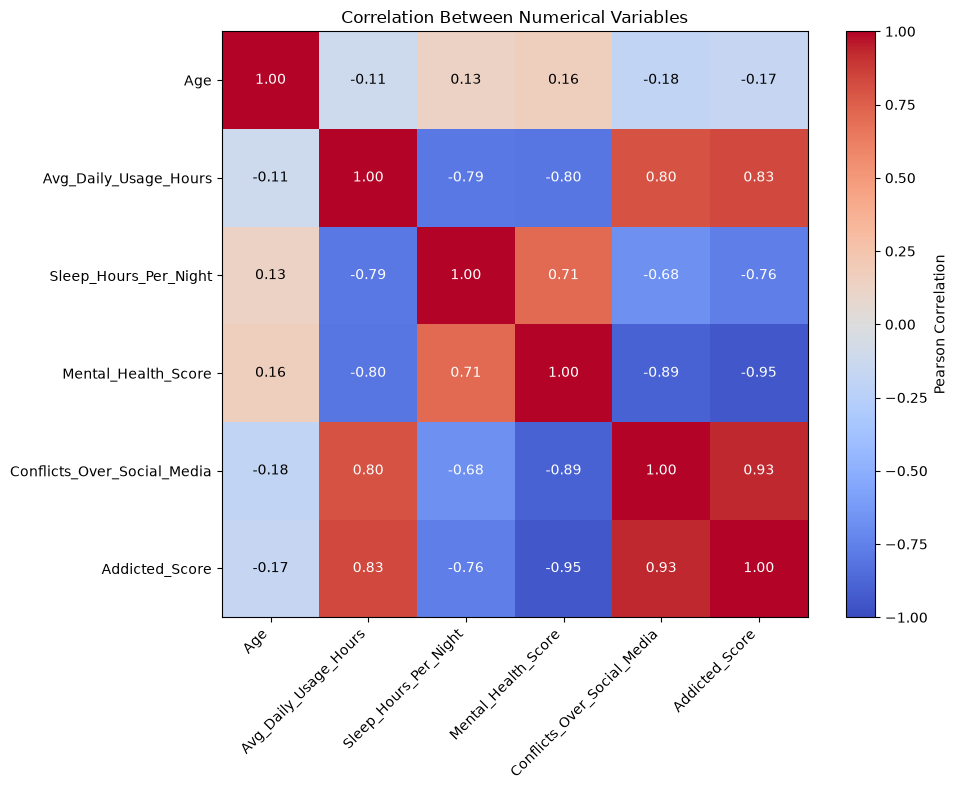

Correlations with Addicted_Score:
Mental_Health_Score           -0.945
Sleep_Hours_Per_Night         -0.765
Age                           -0.166
Avg_Daily_Usage_Hours          0.832
Conflicts_Over_Social_Media    0.934


In [17]:
numeric_data = df_eda.select_dtypes(
    include="number"
).drop(columns="Student_ID")

correlation_matrix = numeric_data.corr()

fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

labels = correlation_matrix.columns

ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=45, ha="right")
ax.set_yticklabels(labels)

for row in range(len(labels)):
    for col in range(len(labels)):
        value = correlation_matrix.iloc[row, col]
        ax.text(
            col, row, f"{value:.2f}",
            ha="center",
            va="center",
            color="white" if abs(value) > 0.6 else "black"
        )

fig.colorbar(heatmap, ax=ax, label="Pearson Correlation")
ax.set_title("Correlation Between Numerical Variables")

plt.tight_layout()
plt.show()

print("Correlations with Addicted_Score:")
print(
    correlation_matrix["Addicted_Score"]
    .drop("Addicted_Score")
    .sort_values()
    .round(3)
    .to_string()
)

### Correlation Findings

Mental_Health_Score has the strongest absolute correlation with
Addicted_Score (-0.945), followed by Conflicts_Over_Social_Media
(0.934). Daily usage is positively associated with addiction score
(0.832), while sleep duration is negatively associated (-0.765).
Age shows a weak negative linear association (-0.166).

These relationships describe this sample and do not establish causation.
Strong correlations alone do not prove data leakage. The dataset
documentation should be checked to determine whether any predictors
were used to construct Addicted_Score.

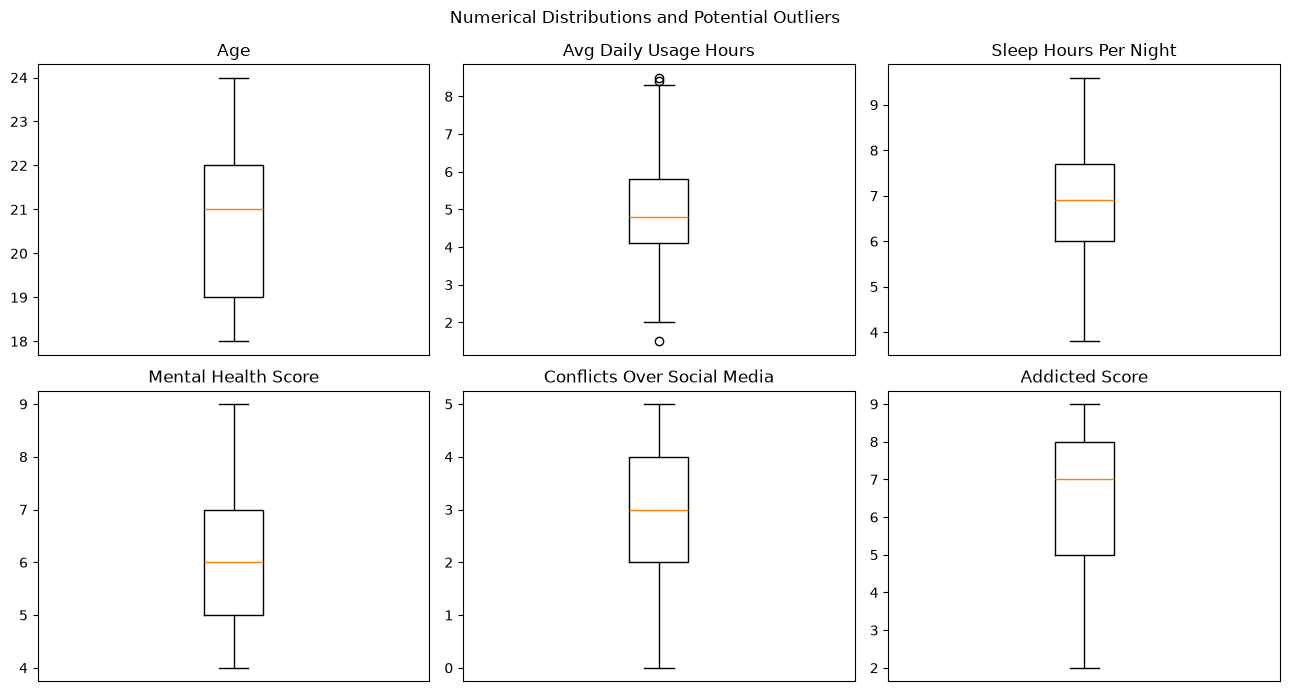

In [18]:
columns = [
    "Age",
    "Avg_Daily_Usage_Hours",
    "Sleep_Hours_Per_Night",
    "Mental_Health_Score",
    "Conflicts_Over_Social_Media",
    "Addicted_Score"
]

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

for ax, column in zip(axes.flat, columns):
    ax.boxplot(df_eda[column].dropna())
    ax.set_title(column.replace("_", " "))
    ax.set_xticks([])

plt.suptitle("Numerical Distributions and Potential Outliers")
plt.tight_layout()
plt.show()

In [19]:
column = "Avg_Daily_Usage_Hours"

q1 = df_eda[column].quantile(0.25)
q3 = df_eda[column].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df_eda[
    (df_eda[column] < lower_bound) |
    (df_eda[column] > upper_bound)
]

print(f"Lower boundary: {lower_bound:.2f} hours")
print(f"Upper boundary: {upper_bound:.2f} hours")
print("Number of flagged records:", len(outliers))

display(
    outliers[
        ["Student_ID", "Avg_Daily_Usage_Hours", "Addicted_Score"]
    ].sort_values(column)
)

Lower boundary: 1.55 hours
Upper boundary: 8.35 hours
Number of flagged records: 3


,Student_ID,Avg_Daily_Usage_Hours,Addicted_Score
6,7,1.5,2
486,487,8.4,9
496,497,8.5,9


### Potential Outlier Findings

Using the 1.5 × IQR rule, three records (0.43% of the dataset)
were flagged for average daily social-media usage. The lower
and upper boundaries were 1.55 and 8.35 hours.

The other five numerical variables showed no outliers under
this rule. Flagged records were retained because statistical
outliers are not necessarily data errors.